In [ ]:
import logging
import warnings

import arviz as az
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np

import hssm

# Keep backend notices out of the static page without hiding sampler warnings.
for _name in ("hssm", "pymc"):
    logging.getLogger(_name).setLevel(logging.WARNING)
warnings.filterwarnings(
    "ignore", message=r"'Model\..*' is deprecated", category=FutureWarning
)
warnings.filterwarnings(
    "ignore",
    message="Numba will use object mode",
    module=r"pytensor\.link\.numba\.",
)
hssm.set_floatX("float64")

# Fit response times and reported directions

Suppose a participant points to the direction of a moving dot. A trial gives
us an RT and an angle, not a correct/incorrect choice. In the circular diffusion
model, evidence starts at the center of a disk. The location where it first
hits the circle gives the angle; the time taken plus nondecision time gives RT.

**Requirements.** This walkthrough needs HSSM 0.5.1 or later, which installs
ssm-simulators 0.17.0 or later, the first release with the circular simulator.

## Simulate one participant

Use the target as the zero direction. A positive `v_x` points toward the
target; a positive `v_y` pulls the mean report counterclockwise. These
are the two components of **one** drift vector. We give it a small sideways
component here. RT is in seconds; the `response` column is an angle in radians
on [−π, π). HSSM reads that circular domain from the simulator's model config;
you don't need an extra column or a plotting option to declare it.

In [ ]:
truth = {"v_x": 1.5, "v_y": 0.5, "a": 1.0, "t": 0.2}
data = hssm.simulate_data(
    "circular_diffusion", theta=truth, size=250, random_state=42
)
mo.Html(data.head().to_html(index=False, float_format="{:.3f}".format))

rt,response
1.053,-0.108
0.907,-0.010
0.894,0.217
0.356,2.544
0.415,-0.863


## Estimate all four parameters

We pass only the observations to the model. HSSM estimates the two drift
components, the decision radius `a`, and nondecision time `t` together.
Unit diffusion noise fixes the scale, and `p_outlier=None` turns off the
lapse mixture. Drift is relative to our chosen target axis; its components
are not separate participant groups or regression slopes.

In [ ]:
model = hssm.HSSM(data=data, model="circular_diffusion", p_outlier=None)
fit = model.sample(
    sampler="pymc",
    chains=4,
    cores=1,
    tune=600,
    draws=600,
    init="adapt_diag",
    target_accept=0.9,
    random_seed=43,
    progressbar=False,
)

In [ ]:
_summary = az.summary(fit, var_names=list(truth), ci_kind="eti", ci_prob=0.95)[
    ["mean", "eti95_lb", "eti95_ub", "ess_bulk", "r_hat"]
].rename(columns={"eti95_lb": "2.5%", "eti95_ub": "97.5%"})
_summary.insert(0, "generating", [truth[_name] for _name in _summary.index])
mo.Html(_summary.to_html())

,generating,mean,2.5%,97.5%,ess_bulk,r_hat
v_x,1.5,1.472,1.272605,1.678112,2028,1.00
v_y,0.5,0.41,0.191224,0.616993,2091,1.00
a,1.0,0.975,0.913754,1.046758,1574,1.00
t,0.2,0.2109,0.188511,0.229427,1716,1.00


## Check both observed outcomes

Simulate new RTs and angles from the fitted model, then use its default
predictive plot. The left panel compares **RT densities**. On the right,
the radius is the **fraction of reports in an angular bin**: a radius of
10% means one report in ten fell in that sector. Each replicate is
normalized separately. The shaded intervals are pointwise across replicated
datasets, not intervals for the drift direction.


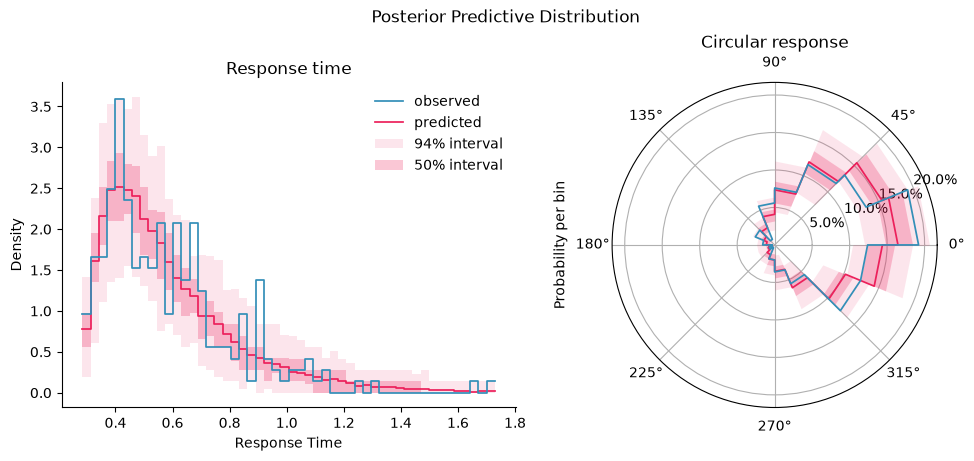

In [ ]:
model.sample_posterior_predictive(draws=np.arange(0, 600, 30), random_seed=44)
rt_ax, _angle_ax = model.plot_predictive()
_figure = rt_ax.figure
plt.close(_figure)
_figure

In the fitted target frame, both drift components are positive: the drift
points toward the target but also to its counterclockwise side. This is
a property of the simulated participant, not a claim about human bias.
Look for shifts in the center or tails of the RT distribution and for
sectors the model consistently over- or under-predicts. Agreement in these
two panels checks the separate distributions of speed and direction; it does
not by itself test whether slower individual reports have larger errors.